# RUL Prediction — NASA IMS Bearing Dataset
### Pipeline: Load → Features → Health Indicator → Save Dataset

## Step 1: Imports

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import skew, kurtosis
from scipy.fft import fft, fftfreq
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.metrics import r2_score
import warnings
warnings.filterwarnings('ignore')
print("All imports OK")



All imports OK


## Step 2: Load NASA IMS Bearing Dataset

NASA IMS Bearing dataset (2nd_test). Each file = one time snapshot of all 4 bearings.
We pick **Bearing 1** (column 0). Sampling frequency = 20,000 Hz.

In [14]:
# ── Set your dataset path here ───────────────────────────────────────────────
try:
    import kagglehub
    _base = kagglehub.dataset_download("vinayak123tyagi/bearing-dataset")
    data_dir = Path(_base) / "2nd_test" / "2nd_test"
    if not data_dir.exists():
        data_dir = Path(_base) / "2nd_test"
except Exception:
    data_dir = Path("./2nd_test")

Fs = 20000
bearing_col = 0
data_paths = sorted(data_dir.glob("*"))
print("Total files:", len(data_paths))
print("First file :", data_paths[0].name)
print("Last file  :", data_paths[-1].name)


Total files: 984
First file : 2004.02.12.10.32.39
Last file  : 2004.02.19.06.22.39


In [15]:
all_segments = []
for fp in data_paths:
    raw = np.loadtxt(fp)
    all_segments.append(raw[:, bearing_col])

vibration = np.concatenate(all_segments)
time      = np.arange(len(vibration)) / Fs

print("Vibration shape:", vibration.shape)
print("Total duration :", round(time[-1], 1), "seconds")


Vibration shape: (20152320,)
Total duration : 1007.6 seconds


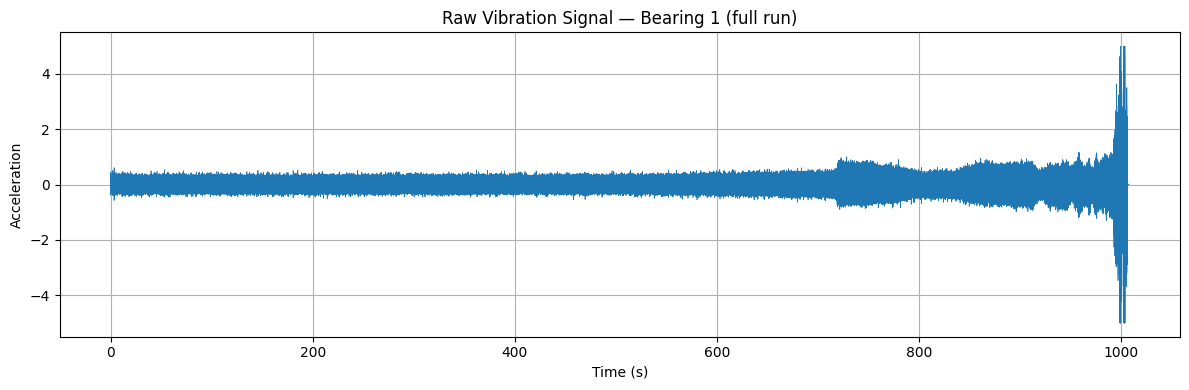

Sampling Frequency: 20000 Hz
Samples per file  : 20480
Number of files   : 984


In [16]:
plt.figure(figsize=(12, 4))
plt.plot(time, vibration, linewidth=0.5)
plt.title("Raw Vibration Signal — Bearing 1 (full run)")
plt.xlabel("Time (s)"); plt.ylabel("Acceleration")
plt.grid(True); plt.tight_layout(); plt.show()

print("Sampling Frequency:", Fs, "Hz")
print("Samples per file  :", len(all_segments[0]))
print("Number of files   :", len(data_paths))


## Step 3: Windowing

Divide the long vibration signal into overlapping windows.
Each window = one degradation snapshot. Window = 5 s, 50% overlap.

In [17]:
fs=20000
window_seconds=5
window_size=fs * window_seconds   # 100,000 samples
step=window_size // 2      # 50% overlap

time_final = []
for i in range(0,len(vibration) - window_size, step):
    t = time[i + window_size // 2]
    time_final.append(t)
time_final = np.array(time_final)

print("Window size (samples):", window_size)
print("Window size (seconds):", window_seconds)
print("Step size   (samples):", step)
print("Total windows        :", len(time_final))


Window size (samples): 100000
Window size (seconds): 5
Step size   (samples): 50000
Total windows        : 402


## Step 4: Feature Extraction

Extract **27 features** per window across 3 domains:
- **Time domain** — 12 features
- **Frequency domain** — 10 features
- **Time-Frequency (Wavelet)** — 5 features

### 4A — Time Domain Features (12)

Time domain features shape: (402, 13)


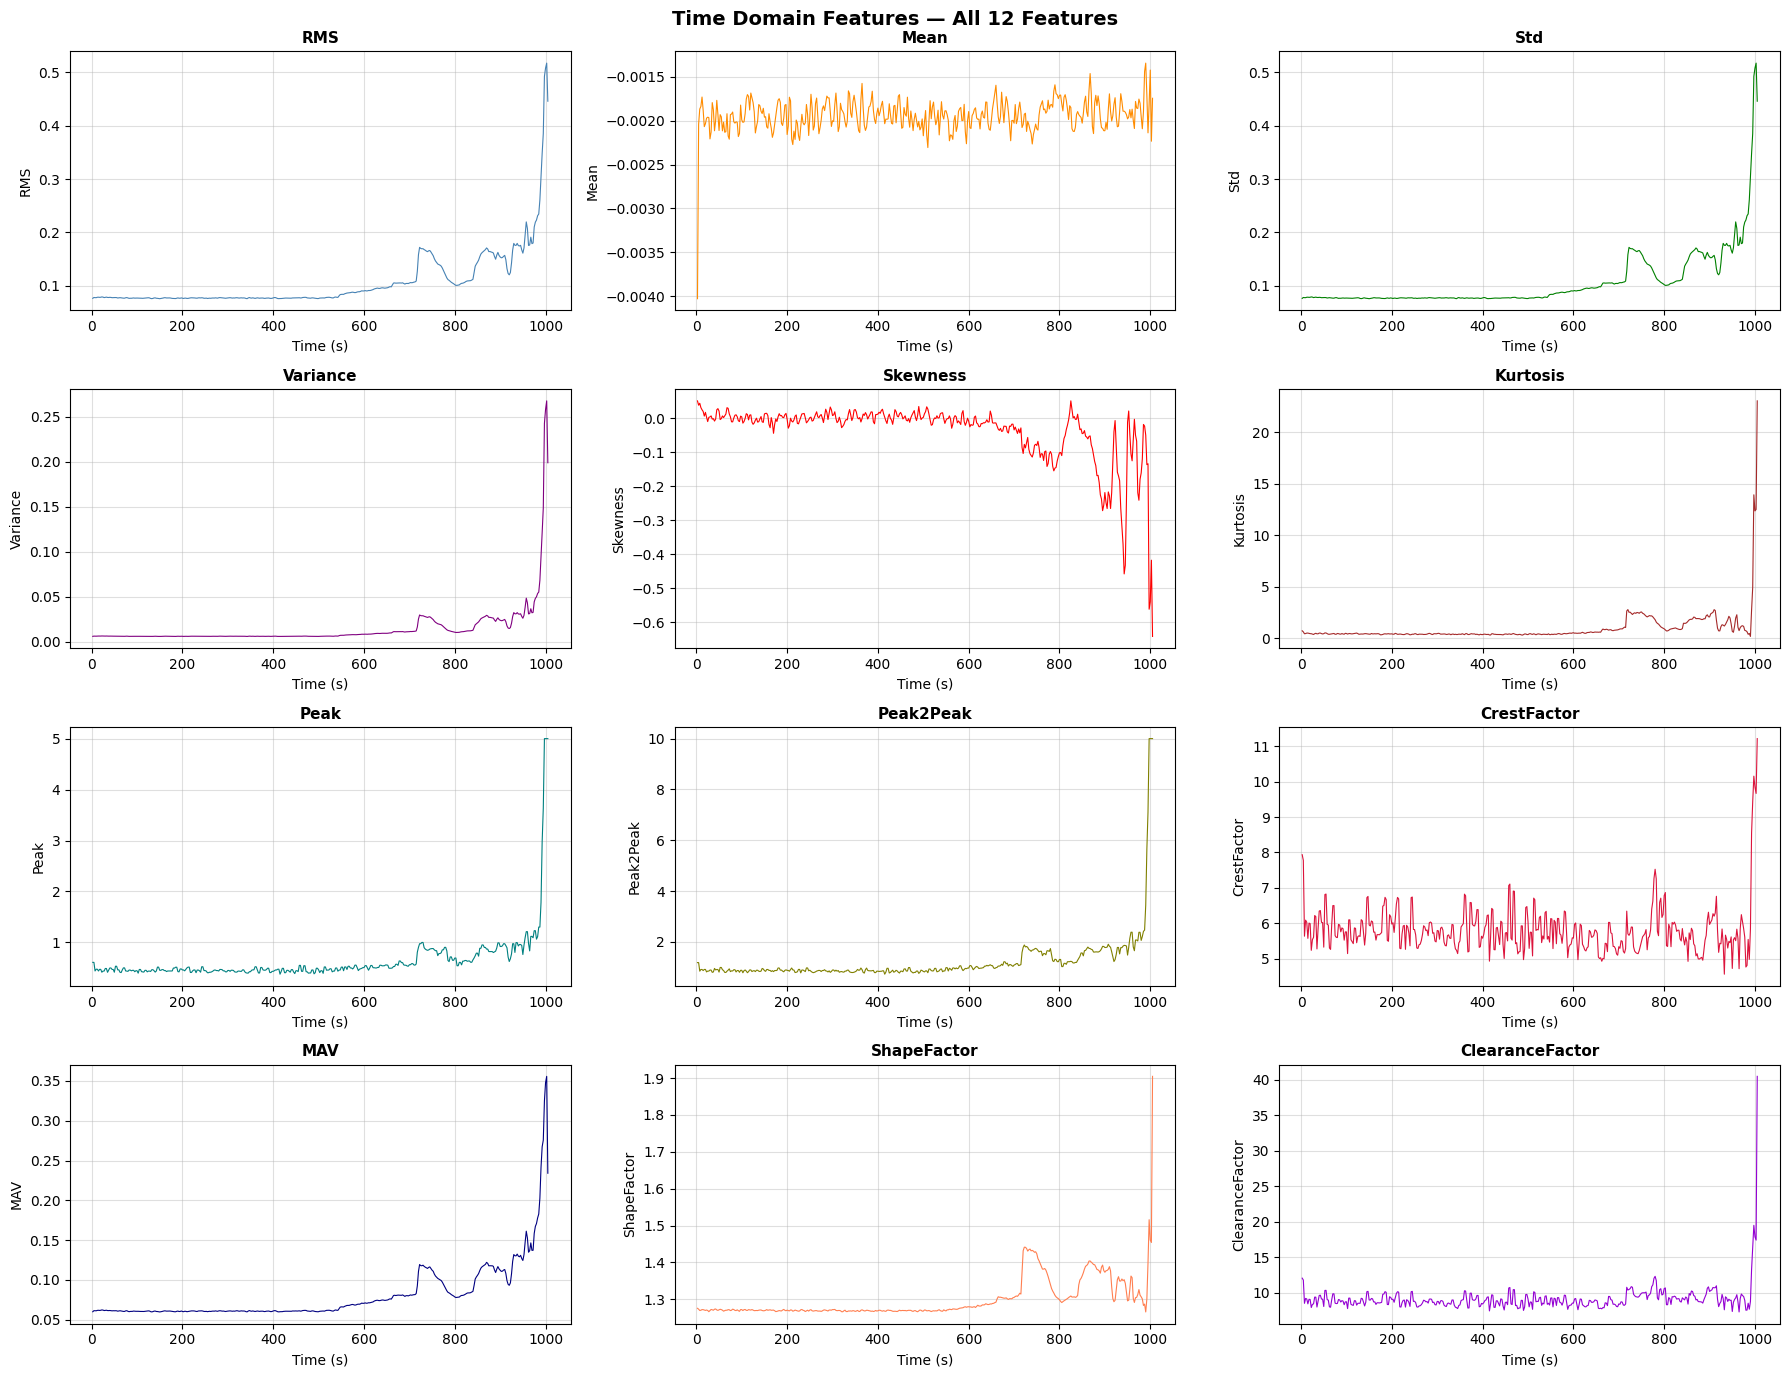

In [30]:
time_features = {}

for i in range(0, len(vibration) - window_size, step):
    seg = vibration[i:i+window_size]
    pass  

# Compute all 12 time-domain features in one pass for efficiency
rms_v, mean_v, std_v, var_v   = [], [], [], []
skew_v, kurt_v, peak_v        = [], [], []
ptp_v, crest_v, mav_v         = [], [], []
sf_v, cf_v                    = [], []

for i in range(0, len(vibration) - window_size, step):
    seg = vibration[i:i+window_size]
    rms_s   = np.sqrt(np.mean(seg**2))
    mav_s   = np.mean(np.abs(seg))
    peak_s  = np.max(np.abs(seg))

    rms_v.append(rms_s)
    mean_v.append(np.mean(seg))
    std_v.append(np.std(seg))
    var_v.append(np.var(seg))
    skew_v.append(skew(seg))
    kurt_v.append(kurtosis(seg))
    peak_v.append(peak_s)
    ptp_v.append(np.max(seg) - np.min(seg))         
    crest_v.append(peak_s / (rms_s + 1e-12))
    mav_v.append(mav_s)
    sf_v.append(rms_s / (mav_s + 1e-12))
    cf_v.append(peak_s / (np.mean(np.sqrt(np.abs(seg)))**2 + 1e-12))

time_features = {
    "RMS": np.array(rms_v), "Mean": np.array(mean_v),
    "Std": np.array(std_v), "Variance": np.array(var_v),
    "Skewness": np.array(skew_v), "Kurtosis": np.array(kurt_v),
    "Peak": np.array(peak_v), "Peak2Peak": np.array(ptp_v),
    "CrestFactor": np.array(crest_v), "MAV": np.array(mav_v),
    "ShapeFactor": np.array(sf_v), "ClearanceFactor": np.array(cf_v),
}

time_df = pd.DataFrame(time_features)
time_df["time"] = time_final
print("Time domain features shape:", time_df.shape)

fig, axes = plt.subplots(4, 3, figsize=(18, 14))
time_feat_names = ["RMS","Mean","Std","Variance","Skewness","Kurtosis",
                   "Peak","Peak2Peak","CrestFactor","MAV","ShapeFactor","ClearanceFactor"]
colors = ['steelblue','darkorange','green','purple','red','brown',
          'teal','olive','crimson','navy','coral','darkviolet']

for ax, feat, col in zip(axes.flat, time_feat_names, colors):
    ax.plot(time_final, time_features[feat], color=col, linewidth=0.8)
    ax.set_title(feat, fontsize=11, fontweight='bold')
    ax.set_xlabel("Time (s)"); ax.set_ylabel(feat)
    ax.grid(True, alpha=0.4)

plt.suptitle("Time Domain Features — All 12 Features", fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()


### 4B — Frequency Domain Features (10)

Frequency domain features shape: (402, 11)


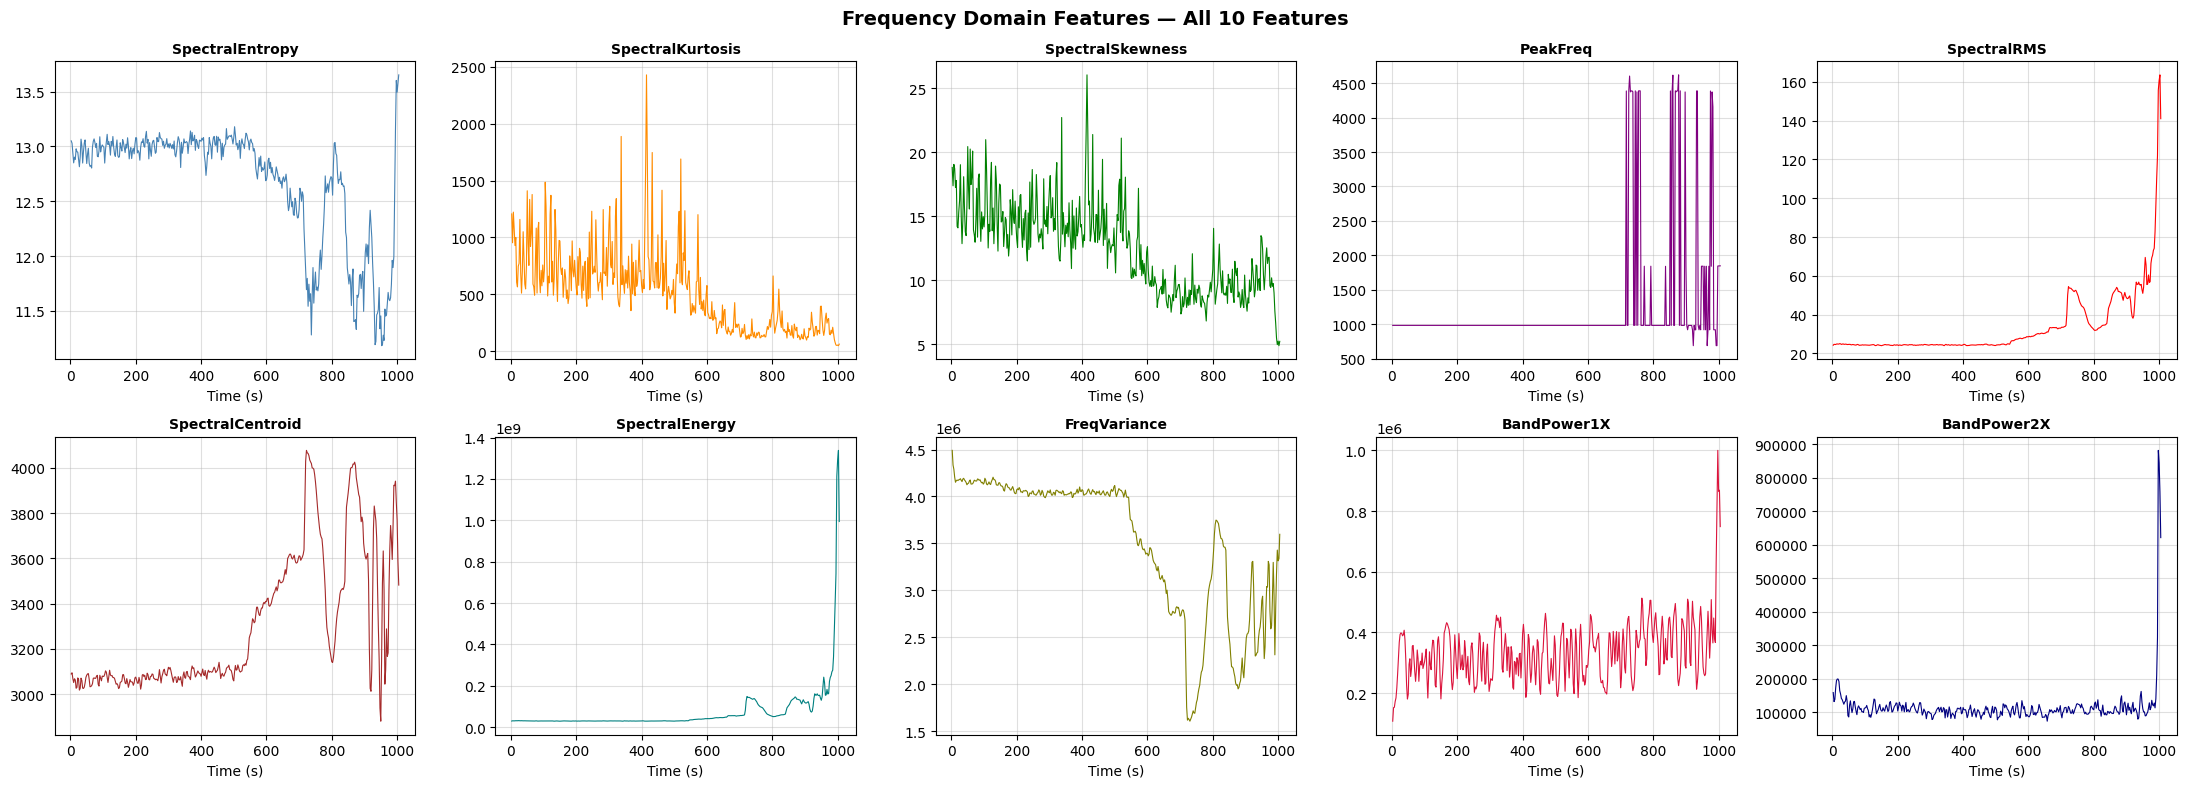

In [31]:
freq_features = {}

se_v, sk_v, ss_v, pf_v, sr_v = [], [], [], [], []
sc_v, seng_v, fv_v, bp1_v, bp2_v = [], [], [], [], []

shaft_hz = 30
freqs_win = fftfreq(window_size, d=1/Fs)[:window_size//2]

for i in range(0, len(vibration) - window_size, step):
    seg      = vibration[i:i+window_size]
    spectrum = np.abs(fft(seg))[:window_size//2]
    psd      = spectrum**2
    psd_norm = psd / (np.sum(psd) + 1e-12)
    centroid = np.sum(freqs_win * psd) / (np.sum(psd) + 1e-12)

    se_v.append(-np.sum(psd_norm * np.log2(psd_norm + 1e-12)))
    sk_v.append(kurtosis(spectrum))
    ss_v.append(skew(spectrum))
    pf_v.append(freqs_win[np.argmax(spectrum)])
    sr_v.append(np.sqrt(np.mean(spectrum**2)))
    sc_v.append(centroid)
    seng_v.append(np.sum(psd))
    fv_v.append(np.sum(((freqs_win - centroid)**2) * psd) / (np.sum(psd) + 1e-12))

    mask1 = (freqs_win > shaft_hz - 5)  & (freqs_win < shaft_hz + 5)
    mask2 = (freqs_win > 2*shaft_hz - 5) & (freqs_win < 2*shaft_hz + 5)
    bp1_v.append(np.sum(psd[mask1]))
    bp2_v.append(np.sum(psd[mask2]))

freq_features = {
    "SpectralEntropy": np.array(se_v), "SpectralKurtosis": np.array(sk_v),
    "SpectralSkewness": np.array(ss_v), "PeakFreq": np.array(pf_v),
    "SpectralRMS": np.array(sr_v), "SpectralCentroid": np.array(sc_v),
    "SpectralEnergy": np.array(seng_v), "FreqVariance": np.array(fv_v),
    "BandPower1X": np.array(bp1_v), "BandPower2X": np.array(bp2_v),
}

freq_df = pd.DataFrame(freq_features)
freq_df["time"] = time_final
print("Frequency domain features shape:", freq_df.shape)

fig, axes = plt.subplots(2, 5, figsize=(22, 8))
freq_feat_names = ["SpectralEntropy","SpectralKurtosis","SpectralSkewness","PeakFreq","SpectralRMS",
                   "SpectralCentroid","SpectralEnergy","FreqVariance","BandPower1X","BandPower2X"]
fcolors = ['steelblue','darkorange','green','purple','red','brown','teal','olive','crimson','navy']

for ax, feat, col in zip(axes.flat, freq_feat_names, fcolors):
    ax.plot(time_final, freq_features[feat], color=col, linewidth=0.8)
    ax.set_title(feat, fontsize=10, fontweight='bold')
    ax.set_xlabel("Time (s)"); ax.grid(True, alpha=0.4)

plt.suptitle("Frequency Domain Features — All 10 Features", fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()


### 4C — Time-Frequency Features via Wavelet (5)

Time-Frequency features shape: (402, 6)


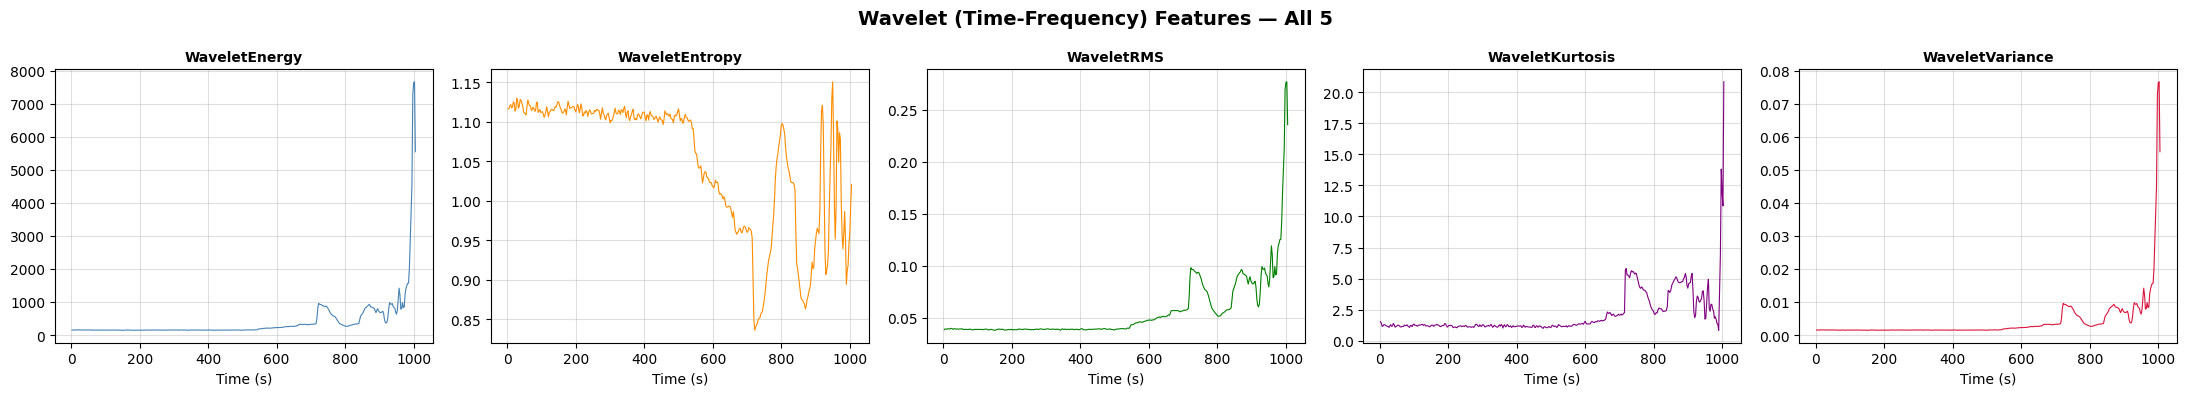

In [34]:
def wavelet_decompose(signal, level=4):
    coeffs, current = [], signal.copy()
    for _ in range(level):
        if len(current) < 2: break
        n = len(current) // 2 * 2
        approx = (current[:n:2] + current[1:n:2]) / 2
        detail = (current[:n:2] - current[1:n:2]) / 2
        coeffs.append(detail)
        current = approx
    coeffs.append(current)
    return coeffs

tf_features = {}
we_v, went_v, wrms_v, wkurt_v, wvar_v = [], [], [], [], []

for i in range(0, len(vibration) - window_size, step):
    seg      = vibration[i:i+window_size]
    coeffs   = wavelet_decompose(seg)
    combined = np.concatenate(coeffs)
    energies = np.array([np.sum(c**2) for c in coeffs])
    prob     = energies / (np.sum(energies) + 1e-12)

    we_v.append(np.sum(energies))
    went_v.append(-np.sum(prob * np.log(prob + 1e-12)))
    wrms_v.append(np.sqrt(np.mean(combined**2)))
    wkurt_v.append(kurtosis(combined))
    wvar_v.append(np.var(combined))

tf_features = {
    "WaveletEnergy": np.array(we_v), "WaveletEntropy": np.array(went_v),
    "WaveletRMS": np.array(wrms_v), "WaveletKurtosis": np.array(wkurt_v),
    "WaveletVariance": np.array(wvar_v),
}

tf_df = pd.DataFrame(tf_features)
tf_df["time"] = time_final
print("Time-Frequency features shape:", tf_df.shape)

fig, axes = plt.subplots(1, 5, figsize=(22, 4))
wf_names = ["WaveletEnergy","WaveletEntropy","WaveletRMS","WaveletKurtosis","WaveletVariance"]
wcolors  = ['steelblue','darkorange','green','purple','crimson']

for ax, feat, col in zip(axes, wf_names, wcolors):
    ax.plot(time_final, tf_features[feat], color=col, linewidth=0.8)
    ax.set_title(feat, fontsize=10, fontweight='bold')
    ax.set_xlabel("Time (s)"); ax.grid(True, alpha=0.4)

plt.suptitle("Wavelet (Time-Frequency) Features — All 5", fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()


## Step 5: Combine All Features

In [21]:
final_df = pd.concat([
    time_df.drop(columns=["time"]),
    freq_df.drop(columns=["time"]),
    tf_df
], axis=1)

print("Final feature matrix shape:", final_df.shape)
print("Columns:", list(final_df.columns))
final_df.head()


Final feature matrix shape: (402, 28)
Columns: ['RMS', 'Mean', 'Std', 'Variance', 'Skewness', 'Kurtosis', 'Peak', 'Peak2Peak', 'CrestFactor', 'MAV', 'ShapeFactor', 'ClearanceFactor', 'SpectralEntropy', 'SpectralKurtosis', 'SpectralSkewness', 'PeakFreq', 'SpectralRMS', 'SpectralCentroid', 'SpectralEnergy', 'FreqVariance', 'BandPower1X', 'BandPower2X', 'WaveletEnergy', 'WaveletEntropy', 'WaveletRMS', 'WaveletKurtosis', 'WaveletVariance', 'time']


,RMS,Mean,Std,Variance,Skewness,Kurtosis,Peak,Peak2Peak,CrestFactor,MAV,...,SpectralEnergy,FreqVariance,BandPower1X,BandPower2X,WaveletEnergy,WaveletEntropy,WaveletRMS,WaveletKurtosis,WaveletVariance,time
0,0.076604,-0.004030,0.076497,0.005852,0.051467,0.733794,0.608,1.184,7.936974,0.060066,...,2.942166e+07,4.490723e+06,107251.226206,159172.030989,146.820502,1.116265,0.038317,1.536056,0.001468,2.5
1,0.078190,-0.002040,0.078163,0.006110,0.038836,0.629359,0.608,1.184,7.775928,0.061425,...,3.058917e+07,4.334322e+06,151990.923636,132176.020425,153.083439,1.116831,0.039126,1.400458,0.001531,5.0
2,0.077893,-0.001867,0.077871,0.006064,0.044530,0.446463,0.439,0.847,5.635931,0.061364,...,3.035409e+07,4.289766e+06,152948.427956,138822.558341,151.132040,1.120375,0.038876,1.149032,0.001511,7.5
3,0.077839,-0.001838,0.077817,0.006056,0.031762,0.466530,0.474,0.913,6.089490,0.061285,...,3.031146e+07,4.205768e+06,172154.406963,172801.314758,150.268224,1.122008,0.038764,1.181460,0.001503,10.0
4,0.078591,-0.001731,0.078572,0.006174,0.025385,0.512199,0.474,0.913,6.031211,0.061795,...,3.089777e+07,4.151410e+06,183971.220180,194937.071276,153.914199,1.117813,0.039232,1.290564,0.001539,12.5


## Step 6: Healthy/Full Split + Normalisation

- First 40% of windows = **Healthy** (used to train PCA model)
- All windows = **Test** (used to detect fault and track degradation)

In [22]:
n_total = len(final_df)
n_healthy = int(0.40 * n_total)   

X_all = final_df.drop(columns=["time"])
X_train = X_all.iloc[:n_healthy]
X_test = X_all

scaler = MinMaxScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
X_test_scaled  = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

print("Total windows  :", n_total)
print("Healthy (train):", n_healthy)
print("Train scaled   :", X_train_scaled.shape)
print("Test  scaled   :", X_test_scaled.shape)

X_train_scaled.head()


Total windows  : 402
Healthy (train): 160
Train scaled   : (160, 27)
Test  scaled   : (402, 27)


,RMS,Mean,Std,Variance,Skewness,Kurtosis,Peak,Peak2Peak,CrestFactor,MAV,...,SpectralCentroid,SpectralEnergy,FreqVariance,BandPower1X,BandPower2X,WaveletEnergy,WaveletEntropy,WaveletRMS,WaveletKurtosis,WaveletVariance
0,0.207134,0.000000,0.182768,0.179571,1.000000,1.000000,1.000000,1.000000,1.000000,0.092602,...,0.669895,0.227681,1.000000,0.000000,0.665902,0.298220,0.558066,0.303355,1.000000,0.297872
1,0.685012,0.810691,0.684457,0.679833,0.867420,0.735701,1.000000,1.000000,0.942320,0.630441,...,0.718716,0.680963,0.689457,0.128073,0.442582,0.728839,0.576145,0.733587,0.736444,0.728951
2,0.595571,0.881051,0.596311,0.591157,0.927188,0.272839,0.202830,0.184019,0.175862,0.606401,...,0.473380,0.589693,0.600989,0.130814,0.497564,0.594667,0.689326,0.600495,0.247756,0.594679
3,0.579292,0.893235,0.580245,0.575030,0.793177,0.323624,0.367925,0.343826,0.338308,0.574981,...,0.313066,0.573141,0.434205,0.185794,0.778648,0.535274,0.741466,0.541306,0.310785,0.535210
4,0.805846,0.936844,0.807541,0.804213,0.726236,0.439201,0.367925,0.343826,0.317435,0.777107,...,0.471789,0.800773,0.326276,0.219621,0.961763,0.785959,0.607501,0.789989,0.522847,0.786145


## Step 7: PCA → Health Indicator (HI)

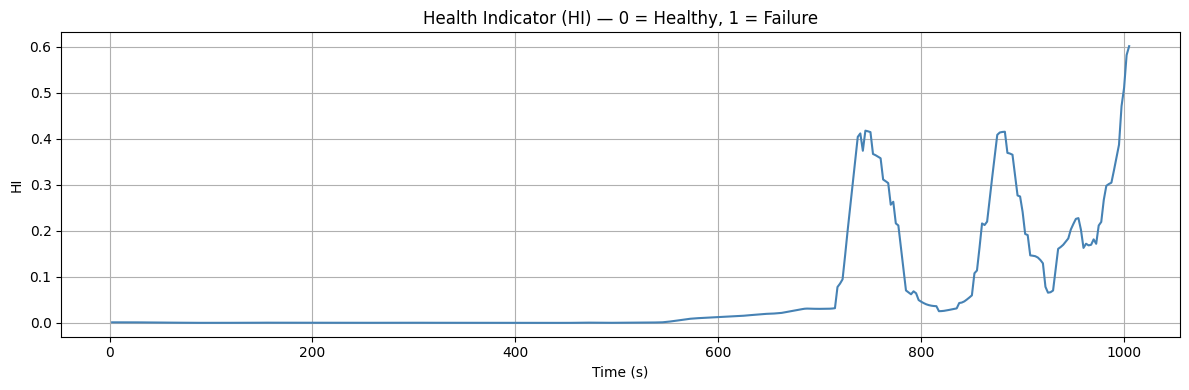

PCA explained variance: ['35.7%', '16.8%', '14.8%', '10.3%', '6.3%', '4.7%', '4.0%', '2.0%']


In [23]:
n_components = 8
pca = PCA(n_components=n_components)
pca.fit(X_train_scaled)

scores_all = pca.transform(X_test_scaled)
weights = pca.explained_variance_ratio_

GPC = scores_all @ weights
HI_raw = np.abs(GPC)
HI = (HI_raw - HI_raw.min()) / (HI_raw.max() - HI_raw.min() + 1e-12)
HI_smooth = pd.Series(HI).rolling(10).mean().bfill()

plt.figure(figsize=(12, 4))
plt.plot(time_final, HI_smooth, color="steelblue")
plt.title("Health Indicator (HI) — 0 = Healthy, 1 = Failure")
plt.xlabel("Time (s)"); plt.ylabel("HI"); plt.grid(True); plt.tight_layout(); plt.show()

print("PCA explained variance:", [f"{v*100:.1f}%" for v in pca.explained_variance_ratio_])


## Step 8: Feature Contribution & Top Features

Top 10 features:
         Feature  Contribution
     BandPower1X      0.179256
 SpectralEntropy      0.178435
SpectralCentroid      0.164327
     ShapeFactor      0.156019
  WaveletEntropy      0.155219
     BandPower2X      0.154292
             MAV      0.149476
      WaveletRMS      0.149017
 WaveletVariance      0.148714
   WaveletEnergy      0.148687


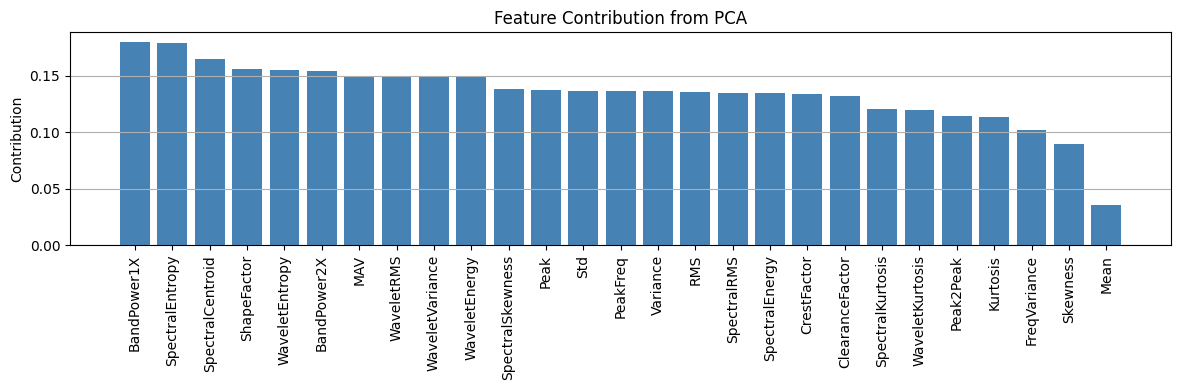


Top features selected: ['BandPower1X', 'SpectralEntropy', 'SpectralCentroid', 'ShapeFactor', 'WaveletEntropy']


In [24]:
loadings = pca.components_
contribution = np.sum(np.abs(loadings) * pca.explained_variance_ratio_[:, np.newaxis], axis=0)

contrib_df = pd.DataFrame({
    "Feature": list(X_train.columns),
    "Contribution": contribution
}).sort_values("Contribution", ascending=False).reset_index(drop=True)

print("Top 10 features:")
print(contrib_df.head(10).to_string(index=False))

plt.figure(figsize=(12, 4))
plt.bar(contrib_df["Feature"], contrib_df["Contribution"], color="steelblue")
plt.xticks(rotation=90); plt.title("Feature Contribution from PCA")
plt.ylabel("Contribution"); plt.tight_layout(); plt.grid(axis="y"); plt.show()

# Select top 5
top_n = 5
top_features = contrib_df["Feature"].iloc[:top_n].tolist()
X_top_train = X_train_scaled[top_features]
X_top_test  = X_test_scaled[top_features]

print("\nTop features selected:", top_features)


## Step 10: Save Dataset to CSV

This is the key step — we save all features + RUL target so the model notebook can load it directly **without re-running feature extraction**.

In [26]:
# ── Build the full dataset to save ──────────────────────────────────────────
dataset = X_test_scaled.copy()
dataset["time"]    = time_final
dataset["HI"]      = HI
dataset["HI_top"]  = HI_top
dataset["RUL_true"] = RUL_true

dataset.to_csv("rul_features_final_dataset.csv", index=False)
print("Dataset saved → rul_features_dataset.csv")
print("Shape:", dataset.shape)
print("Columns:", list(dataset.columns))
dataset.head()


Dataset saved → rul_features_dataset.csv
Shape: (402, 31)
Columns: ['RMS', 'Mean', 'Std', 'Variance', 'Skewness', 'Kurtosis', 'Peak', 'Peak2Peak', 'CrestFactor', 'MAV', 'ShapeFactor', 'ClearanceFactor', 'SpectralEntropy', 'SpectralKurtosis', 'SpectralSkewness', 'PeakFreq', 'SpectralRMS', 'SpectralCentroid', 'SpectralEnergy', 'FreqVariance', 'BandPower1X', 'BandPower2X', 'WaveletEnergy', 'WaveletEntropy', 'WaveletRMS', 'WaveletKurtosis', 'WaveletVariance', 'time', 'HI', 'HI_top', 'RUL_true']


,RMS,Mean,Std,Variance,Skewness,Kurtosis,Peak,Peak2Peak,CrestFactor,MAV,...,BandPower2X,WaveletEnergy,WaveletEntropy,WaveletRMS,WaveletKurtosis,WaveletVariance,time,HI,HI_top,RUL_true
0,0.207134,0.000000,0.182768,0.179571,1.000000,1.000000,1.000000,1.000000,1.000000,0.092602,...,0.665902,0.298220,0.558066,0.303355,1.000000,0.297872,2.5,0.001274,0.041375,1002.5
1,0.685012,0.810691,0.684457,0.679833,0.867420,0.735701,1.000000,1.000000,0.942320,0.630441,...,0.442582,0.728839,0.576145,0.733587,0.736444,0.728951,5.0,0.002094,0.039694,1000.0
2,0.595571,0.881051,0.596311,0.591157,0.927188,0.272839,0.202830,0.184019,0.175862,0.606401,...,0.497564,0.594667,0.689326,0.600495,0.247756,0.594679,7.5,0.000872,0.029383,997.5
3,0.579292,0.893235,0.580245,0.575030,0.793177,0.323624,0.367925,0.343826,0.338308,0.574981,...,0.778648,0.535274,0.741466,0.541306,0.310785,0.535210,10.0,0.000886,0.026120,995.0
4,0.805846,0.936844,0.807541,0.804213,0.726236,0.439201,0.367925,0.343826,0.317435,0.777107,...,0.961763,0.785959,0.607501,0.789989,0.522847,0.786145,12.5,0.001697,0.031366,992.5


In [ ]:
# ── Also save the top-feature subset for quick model loading ─────────────────
top_dataset = pd.DataFrame(X_top_test.values, columns=top_features)
top_dataset["time"]     = time_final
top_dataset["HI_top"]   = HI_top
top_dataset["RUL_true"] = RUL_true


top_dataset.to_csv("rul_top_features_dataset.csv", index=False)
print("Top-feature dataset saved → rul_top_features_dataset.csv")
print("Shape:", top_dataset.shape)

# Quick summary
print("\n=== Dataset Summary ===")
print(f"  Total windows  : {len(dataset)}")
print(f"  Features saved : {len(top_features)} top + 27 full")
print(f"  RUL range      : 0 – {RUL_true.max():.1f}s")
print(f"  Failure time   : {failure_time_top:.1f}s")
print(f"  Fault onset    : {fault_onset_time_top:.1f}s")


Top-feature dataset saved → rul_top_features_dataset.csv
Shape: (402, 8)

=== Dataset Summary ===
  Total windows  : 402
  Features saved : 5 top + 27 full
  RUL range      : 0 – 1002.5s
  Failure time   : 1005.0s
  Fault onset    : 605.0s


## Step 11: Dataset Verification Plot

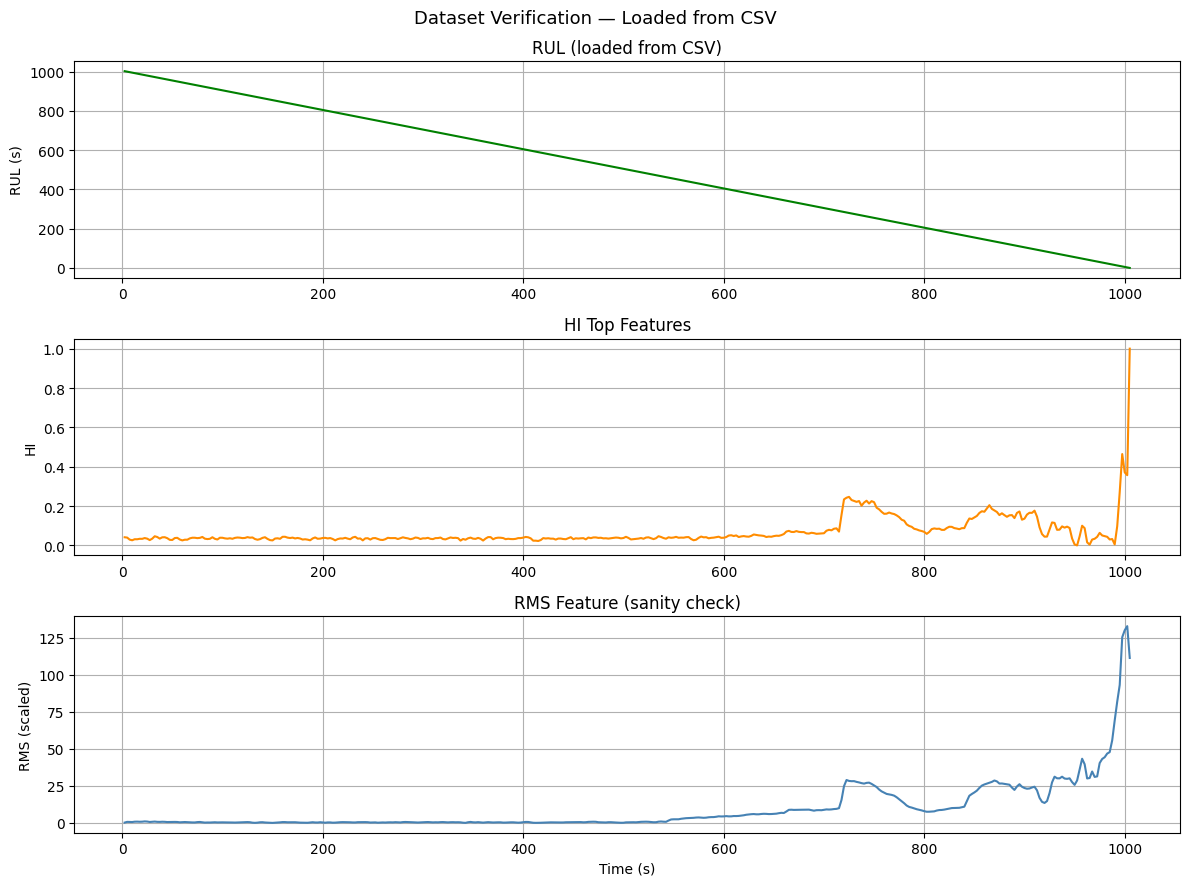

Verification OK — dataset is clean and ready for model training.


In [29]:
df_check = pd.read_csv("rul_features_final_dataset.csv")

fig, axes = plt.subplots(3, 1, figsize=(12, 9))
axes[0].plot(df_check["time"], df_check["RUL_true"], color="green")
axes[0].set_title("RUL (loaded from CSV)"); axes[0].set_ylabel("RUL (s)"); axes[0].grid(True)

axes[1].plot(df_check["time"], df_check["HI_top"], color="darkorange")
axes[1].set_title("HI Top Features"); axes[1].set_ylabel("HI"); axes[1].grid(True)

axes[2].plot(df_check["time"], df_check["RMS"], color="steelblue")
axes[2].set_title("RMS Feature (sanity check)"); axes[2].set_xlabel("Time (s)")
axes[2].set_ylabel("RMS (scaled)"); axes[2].grid(True)

plt.suptitle("Dataset Verification — Loaded from CSV", fontsize=13)
plt.tight_layout(); plt.show()
print("Verification OK — dataset is clean and ready for model training.")
